In [1]:
import numpy as np
import matplotlib.pyplot as plt
from simple_ml_models.knn import KNNClassifier
from sklearn.neighbors import KNeighborsClassifier

# Dataset

In [32]:
# Train dataset
X_train = np.array([
    [1, 1],
    [1, 2],
    [2, 1],
    [2, 2],
    [8, 8],
    [8, 9],
    [9, 8],
    [9, 9],
    [9,1],
    [8,0],
])

y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 2, 2])

# test dataset
X_test = np.array([
    [1.5, 1.5],
    [8.5, 8.5],
    [5, 5],
    [9,1]
])

In [36]:
model = KNNClassifier(n_neighbors=2)
model.fit(X_train, y_train)

sk_model = KNeighborsClassifier(n_neighbors=2)
sk_model.fit(X_train, y_train)

y_pred_custom = model.predict(X_test)
print("Custom KNN predictions:", y_pred_custom)

y_pred_sklearn = sk_model.predict(X_test)
print("Sklearn KNN predictions:", y_pred_sklearn)

print("Are predictions equal?", np.array_equal(y_pred_custom, y_pred_sklearn))

Custom KNN predictions: [0 1 0 2]
Sklearn KNN predictions: [0 1 0 2]
Are predictions equal? True


Plotting the decision boundary

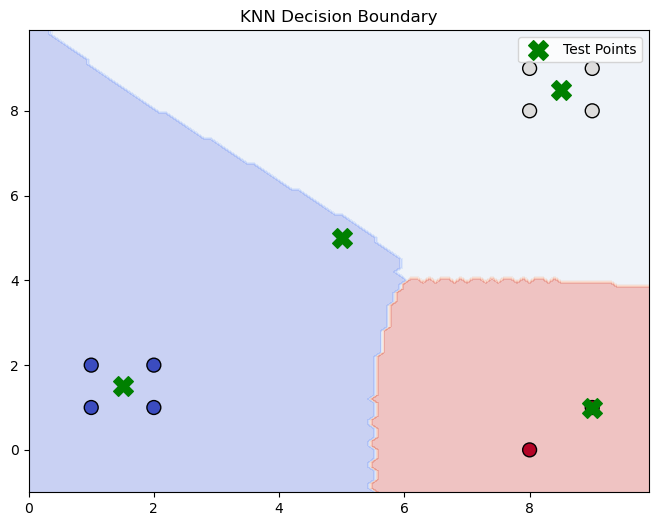

In [38]:
# Creating a meshgrid
h = 0.1  # step size
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

# Predecir para cada punto de la malla
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Graficar frontera
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

# Graficar puntos de entrenamiento
plt.scatter(X_train[:, 0], X_train[:, 1], 
            c=y_train, cmap='coolwarm', edgecolor='k', s=100)

# Graficar puntos de prueba
plt.scatter(X_test[:, 0], X_test[:, 1], 
            c='green', marker='X', s=200, label='Test Points')

plt.title('KNN Decision Boundary')
plt.legend()

In [44]:
np.random.seed(42)

n_train = 5000
n_test = 1000
n_features = 10

X_train = np.random.randn(n_train, n_features)
y_train = np.random.randint(0, 3, size=n_train)

X_test = np.random.randn(n_test, n_features)

In [46]:
import time

In [48]:
model = KNNClassifier(n_neighbors=5)
model.fit(X_train, y_train)

start = time.time()
y_pred_custom = model.predict(X_test)
end = time.time()

print("Custom KNN time:", end - start, "seconds")


Custom KNN time: 0.1660902500152588 seconds


In [50]:
sk_model = KNeighborsClassifier(n_neighbors=5)
sk_model.fit(X_train, y_train)

start = time.time()
y_pred_sklearn = sk_model.predict(X_test)
end = time.time()

print("Sklearn KNN time:", end - start, "seconds")

Sklearn KNN time: 0.14707589149475098 seconds


In [52]:
model.score(X_train, y_train)

0.5474

In [54]:
sk_model.score(X_train, y_train)

0.5474